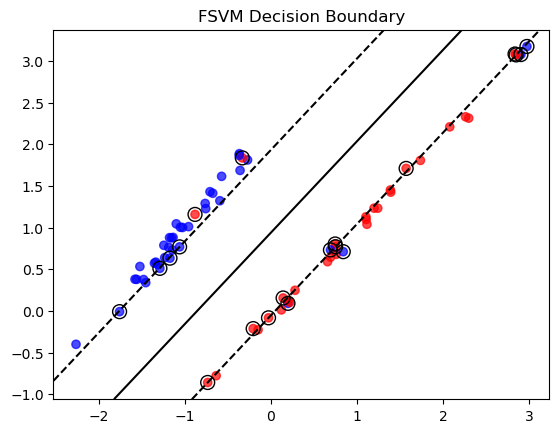

              precision    recall  f1-score   support

          -1       0.71      0.91      0.80        11
           1       0.94      0.79      0.86        19

    accuracy                           0.83        30
   macro avg       0.83      0.85      0.83        30
weighted avg       0.86      0.83      0.84        30



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Generate data
X, y = make_classification(n_samples=100, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, flip_y=0.1, random_state=42)
y = np.where(y == 0, -1, 1)

# Fuzzy memberships
fuzzy_memberships = np.random.uniform(0.5, 1.0, size=y.shape)
fuzzy_memberships[y == -1][:5] = 0.2
fuzzy_memberships[y == 1][:5] = 0.3

# Train/test split
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, fuzzy_memberships, test_size=0.3, random_state=42)

# Train SVM with sample weights
clf = svm.SVC(kernel='linear', C=1.0)
clf.fit(X_train, y_train, sample_weight=s_train)

# Decision boundary
def plot_boundary(X, y, model):
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', alpha=0.7)
    ax = plt.gca()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    xx, yy = np.linspace(*xlim, 30), np.linspace(*ylim, 30)
    YY, XX = np.meshgrid(yy, xx)
    Z = model.decision_function(np.c_[XX.ravel(), YY.ravel()]).reshape(XX.shape)
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], linestyles=['--', '-', '--'])
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=100, edgecolors='k', facecolors='none')
    plt.title("FSVM Decision Boundary")
    plt.show()

plot_boundary(X_train, y_train, clf)

# Evaluation
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))